In [1]:
# importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the dataset

customer_churn = pd.read_csv("../raw_Dataset/raw_customer_churn_data.csv")
customer_churn.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [3]:
customer_churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


In [4]:
# checking for how many missing values are present in each column
customer_churn.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

In [5]:
# selecting rows with missing values
customer_churn[customer_churn.isnull().any(axis=1)]

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes
6,7,60,Male,14,80.32,One-Year,NaN,1124.48,No,Yes
7,8,52,Female,6,58.90,One-Year,NaN,353.40,No,Yes
12,13,47,Male,2,63.26,Two-Year,NaN,126.52,No,Yes
13,14,25,Female,8,71.78,One-Year,NaN,574.24,No,Yes
...,...,...,...,...,...,...,...,...,...,...
990,991,47,Female,9,108.47,Two-Year,NaN,976.23,No,Yes
992,993,42,Female,46,61.09,Month-to-Month,NaN,2810.14,No,Yes
996,997,62,Male,9,80.93,Month-to-Month,NaN,728.37,No,Yes
998,999,39,Male,68,65.67,One-Year,NaN,4465.56,No,Yes


In [6]:
customer_churn.duplicated().sum()

np.int64(0)

In [7]:
customer_churn.dtypes

CustomerID           int64
Age                  int64
Gender              object
Tenure               int64
MonthlyCharges     float64
ContractType        object
InternetService     object
TotalCharges       float64
TechSupport         object
Churn               object
dtype: object

<Axes: xlabel='InternetService', ylabel='count'>

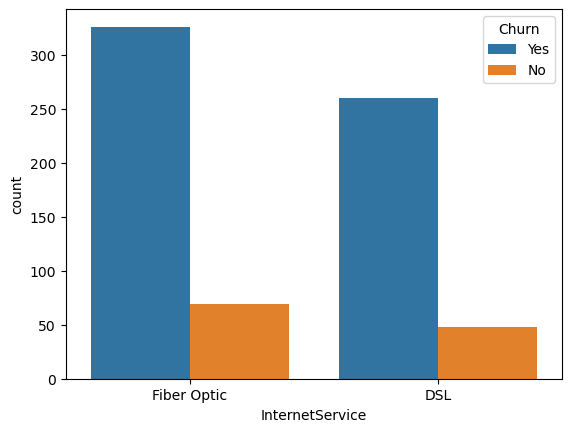

In [8]:
# plotting the cout of internet service types by churn using seaborn
sns.countplot(x='InternetService', hue='Churn', data=customer_churn)

In [9]:
# filling in the missing data in internet service with no internet service
customer_churn['InternetService'] = customer_churn['InternetService'].fillna('No Internet')

In [10]:
# checking for inconsistencies in the data
customer_churn[['Churn','TechSupport', 'ContractType', 'Gender']].value_counts()  

Churn  TechSupport  ContractType    Gender
Yes    Yes          Month-to-Month  Female    138
       No           Month-to-Month  Female    135
                                    Male      130
       Yes          Month-to-Month  Male      108
       No           One-Year        Male       71
                                    Female     67
                    Two-Year        Female     57
       Yes          One-Year        Male       47
No     Yes          One-Year        Female     42
Yes    Yes          Two-Year        Female     40
       No           Two-Year        Male       34
       Yes          One-Year        Female     33
No     Yes          One-Year        Male       29
                    Two-Year        Female     26
Yes    Yes          Two-Year        Male       23
No     Yes          Two-Year        Male       20
Name: count, dtype: int64

In [11]:
customer_churn.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [12]:
#checking for any outliers or negative answers in the numerical columns
customer_churn[(customer_churn['MonthlyCharges'] < 0) | (customer_churn['TotalCharges'] < 0) | (customer_churn['Tenure'] < 0)]

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn


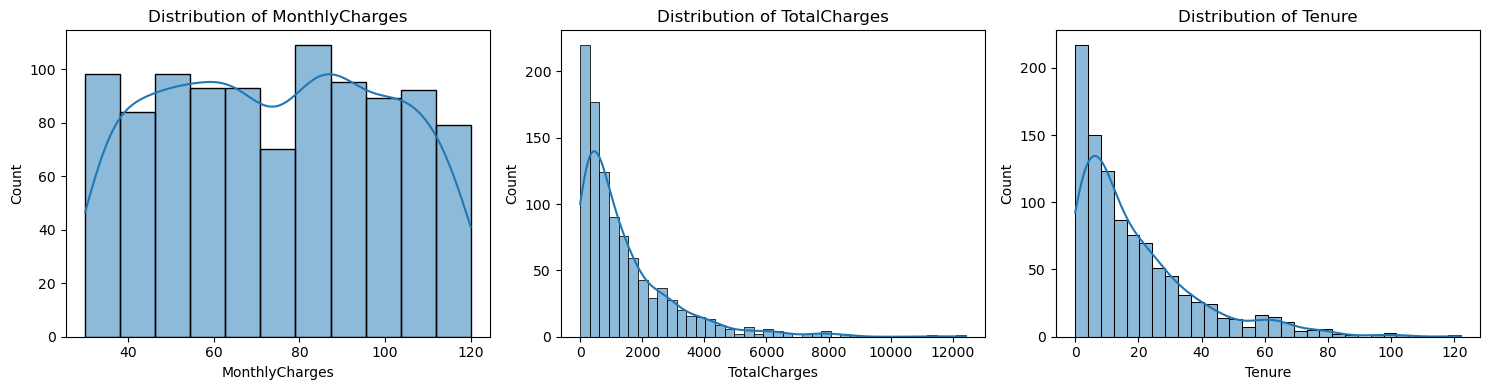

In [13]:
# plotting each numerical column in its own subplot to check for outliers
num_cols = ['MonthlyCharges', 'TotalCharges', 'Tenure']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 row, 3 columns of plots

for ax, col in zip(axes, num_cols):
    sns.histplot(data=customer_churn, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()   # stops titles/labels from overlapping
plt.show()

In [14]:
#checking if total charges is tensure multiplied by monthly charges
customer_churn[customer_churn['TotalCharges'] != customer_churn['Tenure'] * customer_churn['MonthlyCharges']]


,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
15,16,39,Female,41,89.11,Two-Year,Fiber Optic,3653.51,Yes,No
34,35,53,Female,5,85.84,Month-to-Month,DSL,429.20,Yes,Yes
37,38,25,Female,23,47.55,One-Year,Fiber Optic,1093.65,Yes,No
40,41,52,Male,12,111.74,One-Year,Fiber Optic,1340.88,Yes,Yes
48,49,48,Female,56,72.65,One-Year,No Internet,4068.40,No,Yes
...,...,...,...,...,...,...,...,...,...,...
951,952,48,Female,10,40.84,Two-Year,No Internet,408.40,No,Yes
954,955,44,Male,15,64.01,Month-to-Month,Fiber Optic,960.15,No,Yes
978,979,29,Female,36,84.16,Month-to-Month,Fiber Optic,3029.76,Yes,Yes
983,984,44,Male,31,65.26,Month-to-Month,DSL,2023.06,Yes,Yes


In [15]:
# Fixing total charges to be tenure multiplied by monthly charges
customer_churn['TotalCharges'] = customer_churn['Tenure'] * customer_churn['MonthlyCharges']

In [16]:
#save the cleaned data to a new CSV file
customer_churn.to_csv('customer_churn.csv', index=False)